# SlideRule: on-demand ICESat-2 and GEDI processing

[SlideRule](https://slideruleearth.io/) processes satellite altimetry and
lidar data in the cloud. `ea.plugins.sliderule` sends a processor, its
parameters and an area of interest, and returns geolocated points as a
`GeoDataFrame`. SlideRule manages its own credentials.

## Setup

```bash
pip install earthaccess geopandas matplotlib panel holoviews datashader
pip install "earthaccess-plugin-sliderule @ git+https://github.com/betolink/earthaccess-plugin-sliderule"
```

Register at https://slideruleearth.io and use your organization below.

In [9]:
import earthaccess as ea

ea.login()
ea.plugins.sliderule.configure(url="slideruleearth.io", organization="sliderule")
ea.list_plugins(details=True)

name,installed,version,summary
harmony,yes,0.1.0,Subset and transform data with NASA Harmony
pydap,yes,0.1.0,Lazy OPeNDAP access through PyDAP
sliderule,yes,0.1.0,On-demand ICESat-2 and GEDI processing with SlideRule


## Search

A small ATL03 (ICESat-2) region over Greenland.

In [10]:
bbox = (-43.5, 66.5, -43.3, 66.7)  # a small ATL03 region

atl03 = ea.search_data(
    short_name="ATL03",
    bounding_box=bbox,
    temporal=("2023-06-01", "2023-06-30"),
    count=1,
)
len(atl03)

1

## What SlideRule can do

The plugin reports the processors it can run and the subsetting it does:

In [11]:
ea.plugins.sliderule.capabilities("ATL03")

Capabilities('sliderule supported ATL03', operations=3)

## Process with `atl03x`

`request(...).results()` sends the request and returns a `GeoDataFrame`. The searched
granules scope the request; the `aoi` restricts the region.

In [ ]:
aoi = {
    "type": "Polygon",
    "coordinates": [
        [[-43.5, 66.5], [-43.3, 66.5], [-43.3, 66.7], [-43.5, 66.7], [-43.5, 66.5]]
    ],
}

df = ea.plugins.sliderule.request(atl03, api="atl03x", parms={}, aoi=aoi).results()
df.shape

In [ ]:
df.head()

In [ ]:
df.plot(column="height", markersize=0.5)  # geolocated points from SlideRule

## Photon returns: along-track profile

`atl03x` can also classify every photon with the ATL08 algorithm. Passing
`atl08_class` adds the return type (`0` noise, `1` ground, `2` canopy,
`3` top of canopy, `4` unclassified), enough to look at vegetation structure
along a beam.

We pull two ATL03 granules over Boulder, Colorado and cache the returned
`GeoDataFrame` as GeoParquet, so re-running the notebook reuses the local file
instead of re-submitting the SlideRule request.

In [12]:
from pathlib import Path

import geopandas as gpd

# Boulder, Colorado
boulder_bbox = (-105.35, 39.95, -105.15, 40.10)  # west, south, east, north
boulder_aoi = {
    "type": "Polygon",
    "coordinates": [
        [
            [-105.35, 39.95],
            [-105.15, 39.95],
            [-105.15, 40.10],
            [-105.35, 40.10],
            [-105.35, 39.95],
        ]
    ],
}

cache = Path("boulder_photons.parquet")

if cache.exists():
    photons = gpd.read_parquet(cache)  # GeoParquet cache
else:
    atl03_boulder = ea.search_data(
        short_name="ATL03",
        bounding_box=boulder_bbox,
        temporal=("2023-06-01", "2023-08-31"),
        count=2,
    )
    parms_atl08 = {
        # Ask only for classified photons. The 'unclassified' class is mostly
        # possible-TEP noise that would otherwise bury the signal returns.
        "atl08_class": [
            "atl08_noise",
            "atl08_ground",
            "atl08_canopy",
            "atl08_top_of_canopy",
        ],
    }
    photons = ea.plugins.sliderule.request(
        atl03_boulder, api="atl03x", parms=parms_atl08, aoi=boulder_aoi
    ).results()
    photons.to_parquet(cache)  # GeoParquet cache for the next run

photons.shape

(905235, 18)

The returned `GeoDataFrame` has `x_atc` (along-track distance), `height` and
`atl08_class`. Below is a single interactive along-track profile: along-track
distance in kilometres on the X axis, height in metres on the Y axis, and every
photon coloured by its ATL08 return type. The slider resamples the photons.

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
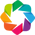

Column
    [0] DiscreteSlider(formatter='%d', label='Sample (%)', name='Sample (%)', options=[1, 2, 5, 10, ...], value=10)
    [1] HTML(str)
    [2] ParamFunction(function, _pane=HoloViews, defer_load=False)

In [13]:
import holoviews as hv
import panel as pn

hv.extension("bokeh")
pn.extension()

return_types = {
    0: "noise",
    1: "ground",
    2: "canopy",
    3: "top of canopy",
}
colors = {
    "noise": "#bdbdbd",
    "ground": "#7f3b08",
    "canopy": "#006d2c",
    "top of canopy": "#41ab5d",
}

returns = photons.assign(
    return_type=photons["atl08_class"].map(return_types),
    along_track_km=photons["x_atc"] / 1000,
).dropna(subset=["return_type"])


def profile(percent):
    """One interactive along-track photon profile for a random `percent` sample."""
    sample = returns.sample(frac=percent / 100, random_state=0)
    layers = [
        hv.Scatter(
            sample.loc[
                sample["return_type"] == name, ["along_track_km", "height"]
            ],
            kdims="along_track_km",
            vdims="height",
            label=name,
        ).opts(color=color, size=2, alpha=0.6)
        for name, color in colors.items()
        if (sample["return_type"] == name).any()
    ]
    y0, y1 = sample["height"].quantile([0.005, 0.995])
    return hv.Overlay(layers).opts(
        title=f"Boulder along-track photon profile — {len(sample):,} photons",
        xlabel="Along-track distance (km)",
        ylabel="Height (m)",
        width=1000,
        height=200,
        ylim=(y0, y1),
        legend_position="right",
    )


sample_slider = pn.widgets.DiscreteSlider(
    name="Sample (%)", options=[1, 2, 5, 10, 25, 50, 100], value=25
)

pn.Column(sample_slider, pn.bind(profile, sample_slider))

## Other processors and parameters

Pass any SlideRule API and its parameters. ICESat-2 APIs include `atl03sp`,
`atl06p`, `atl06sp`, `atl08p`, `atl13sp`, `atl24v`; GEDI APIs include
`gedil1b`, `gedil2a`, `gedil4a`. `parms` is passed through unchanged:

```python
segments = ea.plugins.sliderule.request(
    atl03, api="atl06p", parms={"pass_invalid": False}, aoi=aoi,
).results()
```

You can also run from an `aoi` + `parms` alone, with no search results.

In [ ]:
segments = ea.plugins.sliderule.request(
    atl03, api="atl06p", parms={}, aoi=aoi
).results()
segments.shape

## Unsupported datasets fail early

SlideRule only handles ICESat-2 and GEDI; anything else raises before the
backend is contacted:

In [ ]:
from earthaccess.plugins import UnsupportedCollectionError

mursst = ea.search_data(short_name="MUR-JPL-L4-GLOB-v4.1", count=1)
try:
    ea.plugins.sliderule.request(mursst, api="atl06p").results()
except UnsupportedCollectionError as exc:
    print(exc)

## Which plugins accept a dataset?

In [ ]:
atl03.list_services()

## Summary

- `ea.plugins.sliderule.request(results, api=..., parms=..., aoi=...).results()`
  → `GeoDataFrame`.
- SlideRule keeps its own credentials (`configure(...)`).
- Supports only ICESat-2 and GEDI collections; others fail early.